In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/ai4omics-DataFiles/data/colon_cancer.csv', sep = ';', index_col = 'id_sample')
print(('data', data.shape))

In [ ]:
data.head(10)

# New section

In [ ]:
data.dtypes

In [ ]:
data.describe()

,ADH1C,DHRS11,UGP2,SLC7A5,CTSS,DAO,NIBAN1,PRUNE2,FOXF2,TENT5C,...,SYTL2,BSPRY,CDHR2,ERRFI1,CLIC5,PLLP,GAL,CRYL1,YBX2,ANGPTL4
count,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,...,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000
mean,5.588943,4.354817,5.557694,4.513570,6.717535,7.218184,2.737937,2.806573,3.064394,3.658318,...,3.599294,4.682718,4.225014,4.575397,4.097244,1.823268,2.822931,6.096634,2.801603,2.596452
std,2.889901,1.431179,1.150565,1.614450,1.077821,1.411969,1.466906,1.243826,1.191486,1.258059,...,1.054504,0.917027,1.656088,0.859138,1.276589,0.721587,1.338349,0.840122,1.011971,1.000962
min,0.610504,1.427079,2.027201,1.685024,3.668691,1.164886,0.716737,0.368200,0.610504,0.858074,...,1.286220,1.868389,0.637047,2.250347,1.015235,0.118945,0.610504,2.031471,0.000000,0.757246
25%,3.174250,3.118844,4.611060,3.030022,6.065937,6.241714,1.550382,1.864561,2.198244,2.655091,...,2.878356,4.349295,2.921069,3.958903,3.131267,1.337715,1.840902,5.489589,2.277491,1.824823
50%,5.467024,4.125990,5.412204,4.382953,6.762908,7.578782,2.297732,2.741509,2.900393,3.605686,...,3.613342,4.869313,4.116251,4.537381,3.975276,1.689671,2.591044,6.150297,2.905605,2.442378
75%,8.444756,5.696566,6.556969,5.918848,7.485487,8.263561,3.669509,3.574304,3.752899,4.686086,...,4.417632,5.249372,5.507864,5.070072,5.118110,2.211967,3.661012,6.728052,3.505721,3.139738
max,10.263846,7.022241,7.571114,8.059430,8.990703,10.079135,6.682541,6.591924,6.276628,6.350919,...,5.713776,7.029946,9.045672,7.647284,7.129499,4.763212,7.545757,8.723941,5.169059,6.493643


In [ ]:
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt

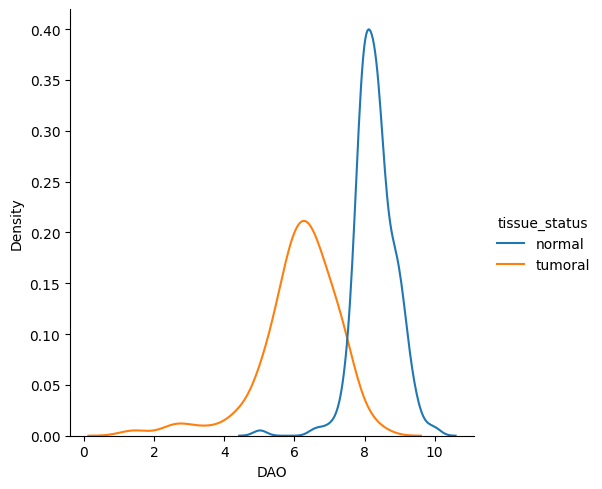

In [ ]:
selected_gene = 'DAO'
sns.displot(data = data, x = selected_gene, hue = 'tissue_status', kind = 'kde')


In [ ]:
features = ['DAO']
x = data[features]
x.head()

,DAO
id_sample,
EPSM-COLON-0001,8.465133
EPSM-COLON-0002,8.159814
EPSM-COLON-0003,8.004194
EPSM-COLON-0004,8.004194
EPSM-COLON-0005,8.056067


In [ ]:
y = data['tissue_status']
print(y)

id_sample
EPSM-COLON-0001     normal
EPSM-COLON-0002     normal
EPSM-COLON-0003     normal
EPSM-COLON-0004     normal
EPSM-COLON-0005     normal
                    ...   
EPSM-COLON-0800    tumoral
EPSM-COLON-0801    tumoral
EPSM-COLON-0802    tumoral
EPSM-COLON-0803    tumoral
EPSM-COLON-0804    tumoral
Name: tissue_status, Length: 804, dtype: object


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 1/3, random_state = 42, stratify = y)
print('Train_dataset:', x_train.shape,'Test_dataset:', x_test.shape)

Train_dataset: (536, 1) Test_dataset: (268, 1)


In [ ]:
x_train.head()

,DAO
id_sample,
EPSM-COLON-0782,5.458151
EPSM-COLON-0754,6.173560
EPSM-COLON-0577,6.870016
EPSM-COLON-0066,7.974447
EPSM-COLON-0706,4.809964


In [ ]:
y_train.head()

,tissue_status
id_sample,
EPSM-COLON-0782,tumoral
EPSM-COLON-0754,tumoral
EPSM-COLON-0577,tumoral
EPSM-COLON-0066,normal
EPSM-COLON-0706,tumoral


In [ ]:
x_test.head()

,DAO
id_sample,
EPSM-COLON-0691,6.543940
EPSM-COLON-0435,7.598907
EPSM-COLON-0508,4.271774
EPSM-COLON-0526,5.580400
EPSM-COLON-0488,8.043821


In [ ]:
y_test.head()

,tissue_status
id_sample,
EPSM-COLON-0691,tumoral
EPSM-COLON-0435,tumoral
EPSM-COLON-0508,tumoral
EPSM-COLON-0526,tumoral
EPSM-COLON-0488,tumoral


In [ ]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier (max_depth =1, random_state = 42, criterion = 'entropy')
classifier.fit(x_train, y_train)



DecisionTreeClassifier(criterion='entropy', max_depth=1, random_state=42)

In [ ]:
from sklearn.tree import export_text, plot_tree
decision_tree_text = export_text(classifier, feature_names=list(x_train.columns))
print(decision_tree_text)

|--- DAO <= 7.54
|   |--- class: tumoral
|--- DAO >  7.54
|   |--- class: normal



[Text(0.5, 0.75, 'DAO <= 7.54\nentropy = 1.0\nsamples = 536\nvalue = [268, 268]\nclass = normal'),
 Text(0.25, 0.25, 'entropy = 0.25\nsamples = 265\nvalue = [11, 254]\nclass = tumoral'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'entropy = 0.29\nsamples = 271\nvalue = [257, 14]\nclass = normal'),
 Text(0.625, 0.5, '  False')]

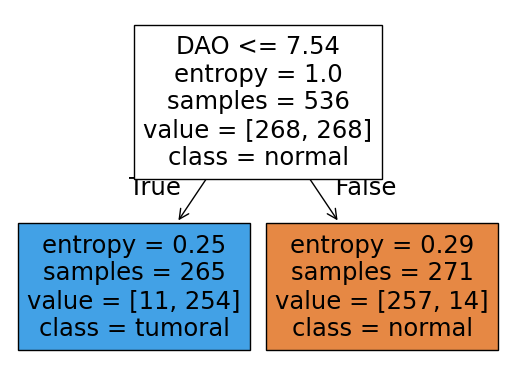

In [ ]:
plot_tree(classifier, feature_names = list(x_train.columns), class_names = y.unique (), precision = 2, filled = True)

In [ ]:
export_text

<function sklearn.tree._export.export_text(decision_tree, *, feature_names=None, class_names=None, max_depth=10, spacing=3, decimals=2, show_weights=False)>

In [ ]:
y_pred_train = classifier.predict(x_train)
y_pred_test = classifier.predict(x_test)

In [ ]:
from sklearn import metrics
accuracy_train = metrics.accuracy_score(y_train, y_pred_train)
accuracy_test = metrics.accuracy_score(y_test, y_pred_test)
print('Train accuracy:', '{:.2f}'.format(accuracy_train), 'Test accuracy:', '{:.2f}'.format(accuracy_test))

Train accuracy: 0.95 Test accuracy: 0.93


In [ ]:
def calculate_accuracy(classifier, x_train, x_test, y_train, y_test):
    classifier.fit(x_train, y_train)
    y_pred_train = classifier.predict(x_train)
    y_pred_test = classifier.predict(x_test)
    accuracy_train = metrics.accuracy_score(y_train, y_pred_train)
    accuracy_test = metrics.accuracy_score(y_test, y_pred_test)
    print('Train accuracy:', '{:.2f}'.format(accuracy_train), 'Test accuracy:', '{:.2f}'.format(accuracy_test))
    return accuracy_train, accuracy_test, classifier

In [ ]:
accuracy_train, accuracy_test, trained_classifier = calculate_accuracy(classifier, x_train, x_test, y_train, y_test)

Train accuracy: 0.95 Test accuracy: 0.93
